# Неорієнтовані графи

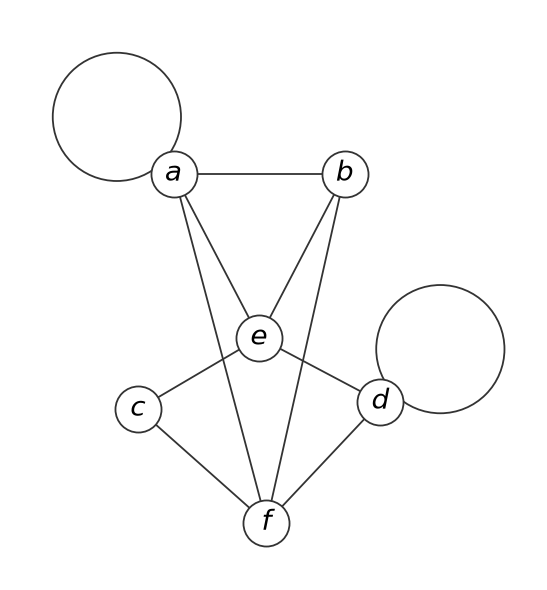

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import networkx as nx

# 1. Створення графа
G = nx.Graph()
nodes = ['a', 'b', 'c', 'd', 'e', 'f']
G.add_nodes_from(nodes)

# Ребра за структурою малюнка:
# (a-f) та (b-f) перетинають ребра (c-e) та (e-d)
edges = [
    ('a', 'b'),
    ('a', 'e'),
    ('b', 'e'),
    ('c', 'e'),
    ('d', 'e'),
    ('a', 'f'),
    ('b', 'f'),
    ('c', 'f'),
    ('d', 'f'),
]
G.add_edges_from(edges)

# Координати вершин (збереження топології перетинів)
pos = {
    'a': (-0.65, 0.95),
    'b': (0.55, 0.95),
    'c': (-0.90, -0.70),
    'd': (0.80, -0.65),
    'e': (-0.05, -0.20),
    'f': (0.00, -1.50),
}

fig, ax = plt.subplots(figsize=(6, 6))

# 2. Малювання ребер графа
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#333333', width=1.3)

# 3. Додавання петель біля вершин 'a' та 'd'
loop_a = patches.Circle((-1.05, 1.35), 0.45, fill=False, edgecolor='#333333', lw=1.3)
loop_d = patches.Circle((1.22, -0.28), 0.45, fill=False, edgecolor='#333333', lw=1.3)
ax.add_patch(loop_a)
ax.add_patch(loop_d)

# 4. Малювання вершин (біле тло перекриває ребра всередині кіл)
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color='white',
    edgecolors='#333333',
    node_size=1100,
    linewidths=1.3
)

# 5. Курсивні підписи літер через MathText ($...$)
labels = {n: f"${n}$" for n in G.nodes()}
nx.draw_networkx_labels(
    G, pos, labels=labels, ax=ax,
    font_size=20,
    font_family='serif'
)

# Рівні пропорції для збереження ідеальної форми кіл
ax.set_aspect('equal')
ax.set_xlim(-1.8, 1.9)
ax.set_ylim(-1.9, 2.1)
ax.axis('off')

plt.tight_layout()
plt.show()

In [31]:
g=G
obj={v:i for i, v in enumerate(g.nodes)}
nodes=list(g.nodes)
size_node=len(nodes)

def adj_matrix(g=None):
    matrix=[[0]*size_node for i in range(size_node)]
    edges=list(g.edges)
    for u, v in edges:
        i,j=obj[u], obj[v]
        matrix[i][j] += 1
        if u != v:
            matrix[j][i]+=1
        if u==v:
            matrix[i][j]=2
            matrix[i][j]=2
    return matrix

matrix_adj=adj_matrix(g)

Пошук в ширину

In [32]:
def bfs(start, matrix_adj):
    queue=[nodes.index(start)]
    visited=[False] * size_node
    visited[queue[0]]=True
    result=[]

    while queue:
        v=queue.pop(0)
        result.append(nodes[v])
        for i in range(size_node):
            if matrix_adj[v][i]>0 and not visited[i]:
                queue.append(i)
                visited[i]=True

    return " -> ".join(result)

print('Пошук в ширину (BFS):')
print(bfs('a', matrix_adj))

print("\nПорівняння з методом бібліотеки networkx (BFS):")
print(" -> ".join( list(nx.bfs_tree(G, source="a").nodes())))

Пошук в ширину (BFS):
a -> b -> e -> f -> c -> d

Порівняння з методом бібліотеки networkx (BFS):
a -> b -> e -> f -> c -> d


Пошук в глибину

In [33]:
def dfs(start, graph):
    stack = [obj[start]]
    visited = set()
    result = []

    while stack:
        vertex = stack.pop()

        if vertex not in visited:
            visited.add(vertex)
            result.append(nodes[vertex])

            for neighbor in reversed(range(size_node)):
                if graph[vertex][neighbor] > 0:
                    if neighbor not in visited:
                        stack.append(neighbor)

    return " -> ".join(result)

print('Пошук в глибину (DFS):')
print(dfs('a',matrix_adj))
print("\nПорівняння з методом бібліотеки networkx (DFS):")
print(" -> ".join( list(nx.dfs_tree(G, source="a").nodes())))

Пошук в глибину (DFS):
a -> b -> e -> c -> f -> d

Порівняння з методом бібліотеки networkx (DFS):
a -> b -> e -> c -> f -> d


# Орієнтовані графи

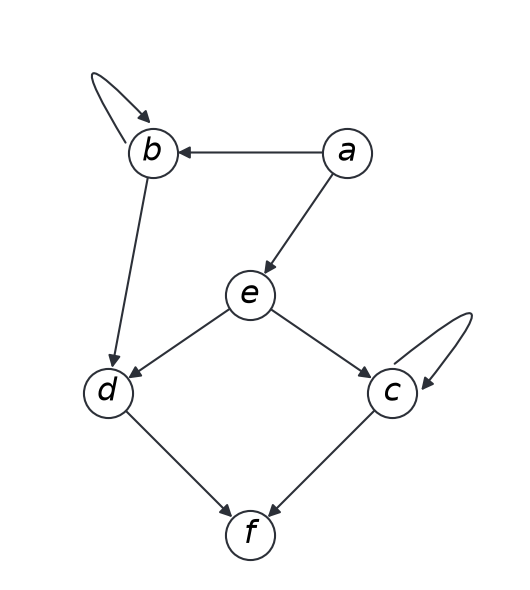

In [34]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import networkx as nx

# 1. Створення графа
G = nx.DiGraph()
nodes = ["a", "b", "c", "d", "e", "f"]
G.add_nodes_from(nodes)

# Координати вершин
pos = {
    "b": (-0.65, 0.95),
    "a": (0.65, 0.95),
    "e": (0.00, 0.00),
    "d": (-0.95, -0.65),
    "c": (0.95, -0.65),
    "f": (0.00, -1.60),
}

# 2. Прямі ребра для зв'язного обходу (з вершини 'a')
edges = [
    ("a", "b"),
    ("a", "e"),
    ("b", "d"),
    ("e", "d"),
    ("e", "c"),
    ("d", "f"),
    ("c", "f"),
]
G.add_edges_from(edges)

# Додаємо кільця (петлі) безпосередньо в структуру графа
loops = [("b", "b"), ("c", "c")]
G.add_edges_from(loops)

# 3. Візуалізація
fig, ax = plt.subplots(figsize=(6, 6))

# Прямі ребра
for u, v in edges:
    arrow = patches.FancyArrowPatch(
        posA=pos[u],
        posB=pos[v],
        arrowstyle="-|>",
        mutation_scale=18,
        color="#2c3038",
        lw=1.5,
        shrinkA=18,
        shrinkB=18,
    )
    ax.add_patch(arrow)

# Кільце для 'b'
loop_b = patches.FancyArrowPatch(
    posA=(-0.82, 1.00),
    posB=(-0.65, 1.13),
    connectionstyle="arc3,rad=-4.8",
    arrowstyle="-|>",
    mutation_scale=18,
    color="#2c3038",
    lw=1.5,
)
ax.add_patch(loop_b)

# Кільце для 'c'
loop_c = patches.FancyArrowPatch(
    posA=(0.95, -0.47),
    posB=(1.13, -0.65),
    connectionstyle="arc3,rad=-4.8",
    arrowstyle="-|>",
    mutation_scale=18,
    color="#2c3038",
    lw=1.5,
)
ax.add_patch(loop_c)

# Вершини
nx.draw_networkx_nodes(
    G,
    pos,
    ax=ax,
    node_color="white",
    edgecolors="#2c3038",
    node_size=1250,
    linewidths=1.5,
)

# Підписи вершин
labels = {n: f"${n}$" for n in G.nodes()}
nx.draw_networkx_labels(
    G, pos, labels=labels, ax=ax, font_size=23, font_family="serif"
)

ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.8)
ax.set_ylim(-1.9, 1.9)
ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
nodes_g=list(G.nodes)
obj={v:i for i,v in enumerate(nodes_g)}
edges=list(G.edges)
nodes=list(G.nodes)
nodes_cnt=len(nodes)

def matrix_adj(G):
    edges=list(G.edges)
    matrix=[[0]*nodes_cnt for i in range(nodes_cnt) ]
    for (u,v) in edges:
        matrix[obj[u]][obj[v]]=1
    return matrix

matrix=matrix_adj(G)

Пошук в ширину

In [37]:
def bfs(G,txt=None, matrix=None):
    visited=[False]*nodes_cnt
    queue=[nodes.index(txt)]
    visited[queue[0]]=True
    result=[]
    while queue:
        current_data=queue.pop(0)
        result.append(nodes[current_data])
        for i in range(nodes_cnt):
            if matrix[current_data][i]> 0 and not visited[i]:
                queue.append(i)
                visited[i]=True

    return " -> ".join(result)

print("Пошук в ширину (BFS):")
print(bfs(G,'a', matrix))
print("\nПорівняння з методом бібліотеки networkx (BFS):")
print(" -> ".join(list(nx.bfs_tree(G, source="a").nodes())))

Пошук в ширину (BFS):
a -> b -> e -> d -> c -> f

Порівняння з методом бібліотеки networkx (BFS):
a -> b -> e -> d -> c -> f


Пошук в глибину

In [40]:
def dfs(start, graph):
    stack = [obj[start]]
    visited = set()
    result = []

    while stack:
        vertex = stack.pop()

        if vertex not in visited:
            visited.add(vertex)
            result.append(nodes[vertex])

            for neighbor in reversed(range(size_node)):
                if graph[vertex][neighbor] > 0:
                    if neighbor not in visited:
                        stack.append(neighbor)

    return " -> ".join(result)

print("Пошук в глибину (DFS):")
print(dfs('a', matrix))

print("\nПорівняння з методом бібліотеки networkx (DFS):")
print(" -> ".join( list(nx.dfs_tree(G, source="a").nodes())))

Пошук в глибину (DFS):
a -> b -> d -> f -> e -> c

Порівняння з методом бібліотеки networkx (DFS):
a -> b -> d -> f -> e -> c
